# S6E10 Step by Step: Airline Satisfaction — Every Concept Explained

This notebook solves the October 2026 Playground competition (**will this airline passenger say they are
satisfied?**) from scratch, and **explains every concept the first time it appears**: what it is, why we need it,
and what it tells us about *this* dataset.

It is written for anyone who wants to *understand* a complete tabular ML workflow, not just copy a score.
If you already know a concept, skip its box.

**What you will find**

| Part | Topics |
|---|---|
| 1. The problem and the data | task type, variable types, target distribution |
| 2. The metric | ROC AUC — what it rewards and what it ignores |
| 3. EDA | what drives satisfaction, the meaning of a `0` rating, train vs test |
| 4. Validation before modelling | overfitting, K-fold, out-of-fold predictions, CV vs leaderboard |
| 5. Model 1: logistic regression | scaling, one-hot encoding, why a linear model struggles here |
| 6. Model 2: LightGBM | gradient boosting, early stopping, where the model is wrong |
| 7. Feature engineering | the original dataset, copied values, target encoding without leakage |
| 8. Interpretation with SHAP | what the model learned, in the language of the problem |
| 9. What helped and what did not | an honest ablation table |
| 10. Summary | key takeaways and a glossary |

**Results at a glance** (5-fold CV, ROC AUC; public leaderboard where submitted)

| Model | CV AUC (mean ± std) | Public LB |
|---|---|---|
| Logistic regression, ratings as numbers | 0.92156 ± 0.00044 | — |
| Logistic regression, ratings one-hot encoded | 0.94859 ± 0.00050 | — |
| LightGBM, raw features | 0.95882 ± 0.00063 | 0.95848 |
| LightGBM + target encoding of the exact flight distance | 0.96009 ± 0.00055 | 0.95973 |

Every number quoted in the text is produced by the code cells of this notebook.

# Part 1 — The problem and the data

## 1.1 What are we predicting?

- **One row = one passenger on one flight**, with who they are, what kind of trip it was, and the scores they gave
  to 13 services (wifi, seat, food…).
- **Target**: `satisfaction` — `True` if the passenger declared themselves satisfied, `False` if they were
  "neutral or dissatisfied".
- **Task type**: binary classification. We submit, for every test passenger, the **probability** of `True`.

> **Concept — binary classification.** The thing we predict has only two possible values. The model does not answer
> "yes" or "no": it answers with a number between 0 and 1, and that number is what gets evaluated here.

The data is **synthetic**: Kaggle generated it with a deep-learning model trained on the
[Binary Aviation Satisfaction (129k)](https://www.kaggle.com/datasets/arseniyshutko/binary-aviation-satisfaction-129k)
dataset, a real passenger survey. Keep this in mind: the patterns we find are the ones the generator put there —
and Part 7 shows that some of them can be exploited.

**To run this notebook on Kaggle**, add that dataset as a second input (*Add Input → search "binary aviation
satisfaction 129k"*). Part 7 needs it.

In [1]:
import time
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)

SEED = 42
N_FOLDS = 5
TARGET = "satisfaction"

# Works on Kaggle (/kaggle/input/...) and locally (../data)
ON_KAGGLE = Path("/kaggle/input").exists()
kaggle_files = list(Path("/kaggle/input").rglob("train.csv")) if ON_KAGGLE else []
DATA = kaggle_files[0].parent if kaggle_files else Path("../data")
OUTPUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
# The original (real) dataset: the only other CSV among the inputs
ORIGINAL = ([p for p in Path("/kaggle/input").rglob("*.csv") if p.parent != DATA][0]
            if ON_KAGGLE else DATA / "original" / "data.csv")

train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
orig = pd.read_csv(ORIGINAL)
y = train[TARGET].astype(int).to_numpy()  # True/False -> 1/0

print(f"train: {train.shape}   test: {test.shape}   original: {orig.shape}")
print("versions -> pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| lightgbm", lgb.__version__, "| matplotlib", matplotlib.__version__)
train.head()

train: (699635, 23)   test: (299844, 22)   original: (129880, 22)
versions -> pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | lightgbm 4.7.0 | matplotlib 3.11.2


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


### Chart style

Charts that may travel on their own use one style: the **title states the conclusion**, a subtitle says what is
measured, guide lines point at what to look at, and a footer names the competition.

In [2]:
DARK_GREY, MID_GREY, GRID, ACCENT = "#333333", "#555555", "#e1e0d9", "#d62728"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"

WIDTH_PX, HEIGHT_PX, DPI = 1600, 900, 100
FOOTER = "Kaggle Playground S6E10 · S6E10 Step by Step: Airline Satisfaction — Every Concept Explained"


def shareable_figure(title, subtitle="", footer=FOOTER, nrows=1, ncols=1, **subplots_kw):
    """Create a 1600x900 figure with a conclusion title, subtitle and footer."""
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(WIDTH_PX / DPI, HEIGHT_PX / DPI), dpi=DPI, **subplots_kw
    )
    fig.suptitle(title, x=0.02, y=0.97, ha="left", fontsize=22, fontweight="bold", color=DARK_GREY)
    if subtitle:
        fig.text(0.02, 0.90, subtitle, ha="left", fontsize=14, color=MID_GREY)
    if footer:
        fig.text(0.02, 0.02, footer, ha="left", fontsize=11, color=MID_GREY)
    for ax in fig.axes:
        style_axes(ax)
    fig.subplots_adjust(left=0.07, right=0.97, top=0.84, bottom=0.12)
    return fig, axes


def style_axes(ax):
    """Dark grey labels and ticks, no top/right spines."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(MID_GREY)
    ax.tick_params(colors=DARK_GREY, labelsize=12)
    ax.xaxis.label.set_color(DARK_GREY)
    ax.yaxis.label.set_color(DARK_GREY)
    ax.xaxis.label.set_size(13)
    ax.yaxis.label.set_size(13)
    ax.set_axisbelow(True)


def annotate(ax, text, xy, xytext, color=ACCENT):
    """Callout with a guide line from the text to the point of interest."""
    ax.annotate(text, xy=xy, xytext=xytext, fontsize=12, color=color,
                arrowprops={"arrowstyle": "-", "color": color, "lw": 1.2})


def pct(v, decimals=0):
    return f"{v * 100:.{decimals}f}%"


PCT_TICKS = np.arange(0, 1.01, 0.2)

## 1.2 Data dictionary: what each column means

There are 21 features, in four groups:

| Group | Columns | What they are |
|---|---|---|
| Who | `Gender`, `Age`, `Customer Type` | `Customer Type` is loyal / disloyal (a returning customer or not) |
| The trip | `Type of Travel`, `Class`, `Flight Distance` | business or personal; Business, Eco or Eco Plus; distance in miles |
| 13 service ratings | `Inflight wifi service`, `Seat comfort`, `Online boarding`… | a score from 1 to 5 given by the passenger — plus a mysterious `0` (Part 3) |
| Delays | `Departure Delay in Minutes`, `Arrival Delay in Minutes` | minutes of delay |

> **Concept — numeric vs categorical features.** A *numeric* feature has an order and a distance (age 40 is between
> 30 and 50). A *categorical* feature is just a label (`Eco`, `Business`). The ratings sit in between: they are
> numbers, but Part 3 shows that their order does not behave the way you would expect. That matters when we choose
> a model.

In [3]:
FEATURES = [c for c in test.columns if c != "id"]
CATEGORICAL = train[FEATURES].select_dtypes(exclude="number").columns.tolist()
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
RATINGS = [c for c in NUMERIC if train[c].max() <= 5]
DIST, DEP, ARR = "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"

print(f"{len(FEATURES)} features: {len(CATEGORICAL)} categorical, {len(RATINGS)} ratings, "
      f"{len(NUMERIC) - len(RATINGS)} other numeric")
pd.DataFrame({
    "dtype": train[FEATURES].dtypes.astype(str),
    "n_unique": train[FEATURES].nunique(),
    "min": [train[c].min() for c in FEATURES],
    "max": [train[c].max() for c in FEATURES],
    "nulls_train": train[FEATURES].isna().sum(),
    "nulls_test": test[FEATURES].isna().sum(),
})

21 features: 4 categorical, 13 ratings, 4 other numeric


,dtype,n_unique,min,max,nulls_train,nulls_test
Age,int64,75,7,85,0,0
Flight Distance,int64,3474,67,4983,0,0
Inflight wifi service,int64,6,0,5,0,0
Departure/Arrival time convenient,int64,6,0,5,0,0
Ease of Online booking,int64,6,0,5,0,0
Gate location,int64,6,0,5,0,0
Food and drink,int64,6,0,5,0,0
Online boarding,int64,6,0,5,0,0
Seat comfort,int64,6,0,5,0,0
Inflight entertainment,int64,6,0,5,0,0


Three things to notice in that table: the ratings go from **0** to 5, not from 1 to 5; the only column with missing
values is `Arrival Delay in Minutes`; and `Flight Distance` takes a few thousand distinct values, far fewer than the
number of rows — it will come back in Part 7.

## 1.3 The target

In [4]:
BASE = y.mean()
print(f"satisfied: {BASE:.4%} of {len(y):,} passengers")
pd.Series(y).map({1: "satisfied", 0: "neutral or dissatisfied"}).value_counts().to_frame("passengers")

satisfied: 44.3573% of 699,635 passengers


,passengers
neutral or dissatisfied,389296
satisfied,310339


**44.4% of passengers are satisfied.** The two classes are close to balanced, so we do not need any of the special
techniques for rare classes.

> **Concept — base rate.** The share of positives in the whole dataset. It is the number to beat: any group with a
> satisfaction rate far from 44.4% tells us something. We will use it as the reference line in every chart.

# Part 2 — The metric: ROC AUC

Submissions are scored with the **area under the ROC curve** (AUC) between the predicted probability and the true
label. The name is intimidating; the idea is not.

> **Concept — ROC AUC.** Pick one satisfied passenger and one dissatisfied passenger at random, and look at the
> score the model gave to each. If the satisfied one has the higher score, the model got that pair right. **The AUC
> is the share of pairs the model gets right** (a tie counts as half a pair). 1.0 means every pair is right; 0.5
> means the model does no better than a coin.

**A worked example with four passengers**

| Passenger | Really satisfied? | Score given by the model |
|---|---|---|
| Ana | yes | 0.9 |
| Luis | yes | 0.4 |
| Marta | no | 0.6 |
| Pedro | no | 0.1 |

There are four pairs, each made of one satisfied and one dissatisfied passenger:

- Ana (0.9) against Marta (0.6): right.
- Ana (0.9) against Pedro (0.1): right.
- Luis (0.4) against Pedro (0.1): right.
- Luis (0.4) against Marta (0.6): **wrong** — the dissatisfied passenger got the higher score.

Three pairs right out of four: **AUC = 0.75**.

Three practical consequences follow, and the next cell checks each of them, first on these four passengers and then
on the real data:

1. **A model that knows nothing scores 0.5.** Give everybody the same score and every pair is a tie; a tie counts
   as half, so the AUC is exactly 0.5. Give everybody a random score and about half of the pairs come out right by
   luck, so the AUC is close to 0.5. That is the floor.
2. **Only the order matters, not the numbers.** Multiply the four scores by 100 (90, 40, 60, 10): Ana is still above
   Marta and Luis is still below her. The same pairs are right, so the AUC is still 0.75. Two things follow:
   - there is **no threshold to choose** ("above 0.5 I call them satisfied"): the AUC never uses one;
   - the scores do **not have to be accurate probabilities**. Saying 0.9 or 0.7 makes no difference, as long as the
     satisfied passengers end up above the others.
3. **A single raw column is already a model.** Since only the order matters, we can take a column as it is — say,
   the 0-to-5 rating for online boarding — and use it as if it were the prediction, without training anything.
   That tells us how much signal there is before we start, and gives a number our model has to beat.

In [5]:
def score(y_true, y_pred):
    return roc_auc_score(y_true, y_pred)


# The four passengers of the example: Ana, Luis, Marta, Pedro
toy_truth = np.array([1, 1, 0, 0])
toy_score = np.array([0.9, 0.4, 0.6, 0.1])
print("Four passengers")
print(f"  scores 0.9, 0.4, 0.6, 0.1:      {score(toy_truth, toy_score):.2f}")
print(f"  the same scores times 100:      {score(toy_truth, 100 * toy_score):.2f}")
print(f"  the same score for everybody:   {score(toy_truth, np.full(4, 0.5)):.2f}")

rng = np.random.default_rng(SEED)
x = train["Online boarding"].to_numpy()
print(f"\nReal data ({len(y):,} passengers)")
print(f"  the same score for everybody:   {score(y, np.full(len(y), BASE)):.5f}")
print(f"  a random score:                 {score(y, rng.random(len(y))):.5f}")
print(f"  the 'Online boarding' rating:   {score(y, x):.5f}")
print(f"  that rating times 100, plus 7:  {score(y, 100 * x + 7):.5f}")
print(f"  that rating cubed:              {score(y, x ** 3):.5f}")

single = pd.Series({c: score(y, train[c].fillna(train[c].median())) for c in NUMERIC}).sort_values(ascending=False)
single.round(5).to_frame("AUC of the raw column alone")

Four passengers
  scores 0.9, 0.4, 0.6, 0.1:      0.75
  the same scores times 100:      0.75
  the same score for everybody:   0.50

Real data (699,635 passengers)


  the same score for everybody:   0.50000


  a random score:                 0.49914
  the 'Online boarding' rating:   0.84039


  that rating times 100, plus 7:  0.84039
  that rating cubed:              0.84039


,AUC of the raw column alone
Online boarding,0.84039
Inflight entertainment,0.74453
Seat comfort,0.73212
On-board service,0.69933
Flight Distance,0.69559
Cleanliness,0.68938
Leg room service,0.68770
Inflight wifi service,0.66266
Baggage handling,0.65491
Checkin service,0.63553


The four passengers give 0.75, as counted by hand, and multiplying their scores by 100 changes nothing. On the real
data, the same score for everybody gives exactly 0.5 and a random score gives 0.499.

The `Online boarding` rating **alone** reaches an AUC of 0.840: passengers who found online boarding easy are much
more often satisfied. Rescaling it or cubing it leaves the AUC untouched, because neither changes the order.
Whatever we build has to beat 0.840.

At the bottom of the table, the two delay columns and `Departure/Arrival time convenient` score *below* 0.5 — more
delay goes with slightly less satisfaction, so the raw column ranks passengers the wrong way round. A score of 0.48
is as informative as 0.52; what carries no information is 0.50.

# Part 3 — EDA: what drives satisfaction?

> **Concept — EDA (exploratory data analysis).** Looking at the data before modelling, with one goal: to find out
> what the model will have to deal with. Each chart below answers one question and ends with a conclusion.

## 3.1 Do higher ratings mean more satisfaction? What is a `0`?

The ratings are officially 1 to 5, yet 6.4% of the rows have at least one `0`. The chart shows, for each service and
each score, the share of satisfied passengers.

rows with at least one 0 rating: 6.39%


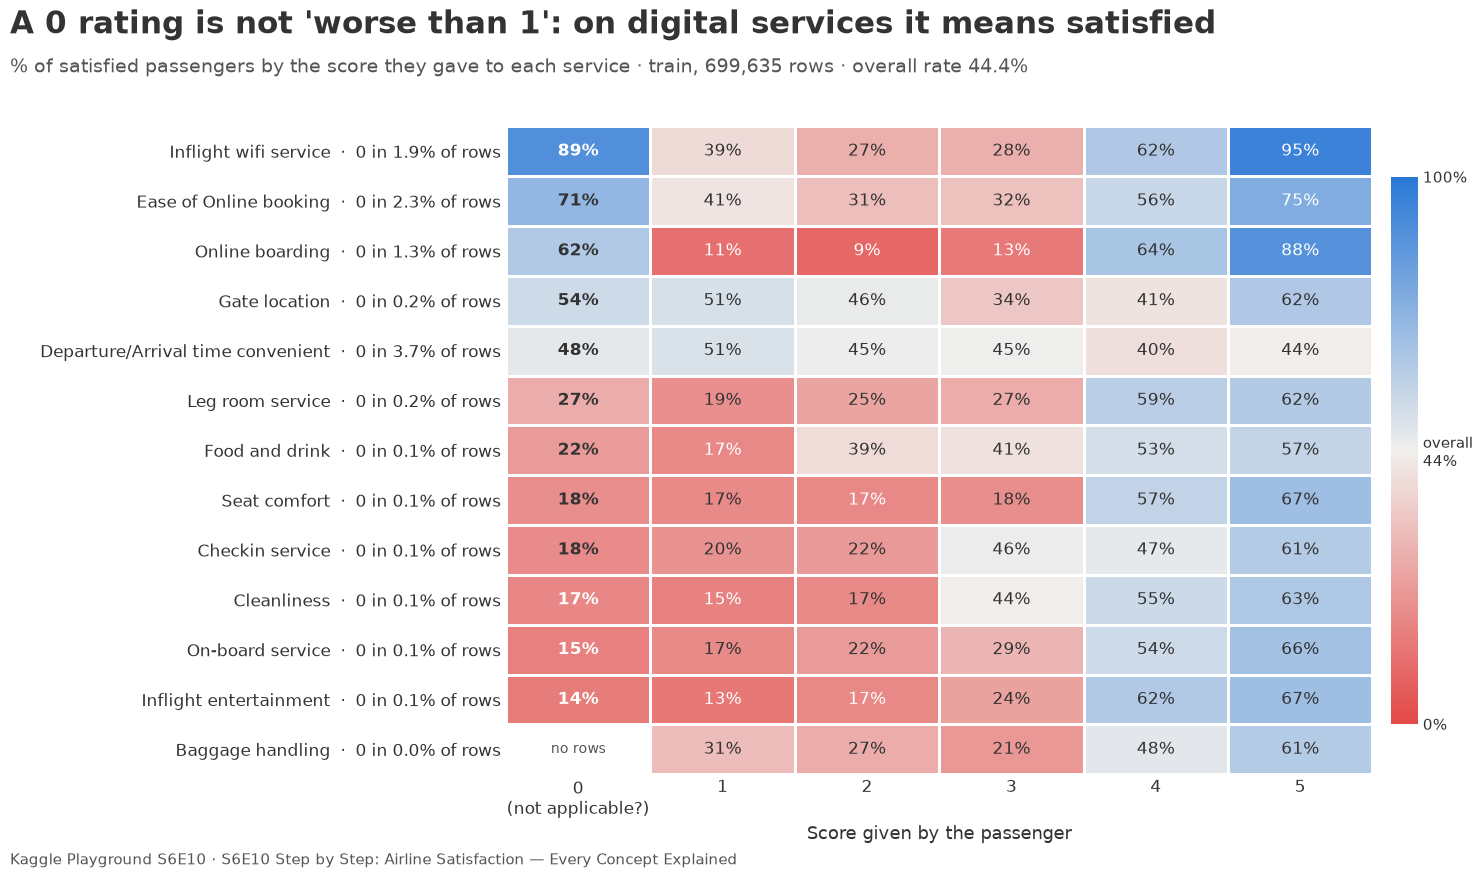

In [6]:
rate = pd.DataFrame({c: pd.Series(y).groupby(train[c].to_numpy()).mean() for c in RATINGS}).T.reindex(columns=range(6))
rate = rate.sort_values(0, ascending=False, na_position="last")
zero_share = (train[RATINGS] == 0).mean()
print(f"rows with at least one 0 rating: {((train[RATINGS] == 0).sum(axis=1) > 0).mean():.2%}")

fig, ax = shareable_figure(
    title="A 0 rating is not 'worse than 1': on digital services it means satisfied",
    subtitle=f"% of satisfied passengers by the score they gave to each service · train, {len(train):,} rows · "
             f"overall rate {pct(BASE, 1)}",
)
cmap = LinearSegmentedColormap.from_list("diverging", [RED, NEUTRAL, BLUE])
norm = TwoSlopeNorm(vmin=0.0, vcenter=BASE, vmax=1.0)
ax.pcolormesh(np.arange(7), np.arange(len(rate) + 1), np.ma.masked_invalid(rate.to_numpy()),
              cmap=cmap, norm=norm, edgecolors="white", linewidth=2)
for i, (_, row) in enumerate(rate.iterrows()):
    for j, v in enumerate(row):
        if np.isnan(v):
            ax.text(j + 0.5, i + 0.5, "no rows", ha="center", va="center", fontsize=10, color=MID_GREY)
            continue
        ax.text(j + 0.5, i + 0.5, pct(v), ha="center", va="center", fontsize=12,
                color="white" if abs(v - BASE) > 0.27 else DARK_GREY, fontweight="bold" if j == 0 else "normal")
ax.set_xticks(np.arange(6) + 0.5, ["0\n(not applicable?)", "1", "2", "3", "4", "5"])
ax.set_yticks(np.arange(len(rate)) + 0.5, [f"{c}  ·  0 in {pct(zero_share[c], 1)} of rows" for c in rate.index])
ax.invert_yaxis()
ax.set_xlabel("Score given by the passenger")
ax.tick_params(length=0)
ax.spines[["left", "bottom"]].set_visible(False)
fig.subplots_adjust(left=0.33, right=0.90)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.03, pad=0.02, ticks=[0, BASE, 1])
cb.ax.set_yticklabels(["0%", f"overall\n{pct(BASE)}", "100%"])
cb.ax.tick_params(labelsize=11, colors=DARK_GREY, length=0)
cb.outline.set_visible(False)
plt.show()

Three conclusions:

- **A `0` is not a bad score.** With `Inflight wifi service = 0`, 89% of passengers are satisfied — more than with
  any score from 1 to 4. The same happens with online booking (71%) and online boarding (62%). A plausible reading
  is that `0` means *"not applicable / did not use it"*; the data does not say so explicitly, so we keep it as a
  hypothesis. For the services everybody uses (seat, cleanliness, entertainment) a `0` is very rare (0.1% of rows)
  and behaves like a `1`. Ιωάννης Σταμελιάς reported this anomaly in the competition forum before this notebook was
  published ([discussion](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/744809)); the
  numbers here were computed independently and agree with his.
- **The scores are not monotonic.** For wifi the satisfaction rate goes 39% → 27% → 28% → 62% → 95% from score 1 to
  5. Scores 1, 2 and 3 are roughly the same thing ("not good"); the jump is between 3 and 4.
- **Some ratings barely matter.** `Departure/Arrival time convenient` stays between 40% and 51% whatever the score.

**Consequence for modelling:** a model that assumes "one more point = a fixed amount more satisfaction" (a linear
model on the raw scores) starts with a handicap. A tree model can cut each score wherever it wants. We measure the
size of that handicap in Part 5.

## 3.2 Who is satisfied? Type of travel and class

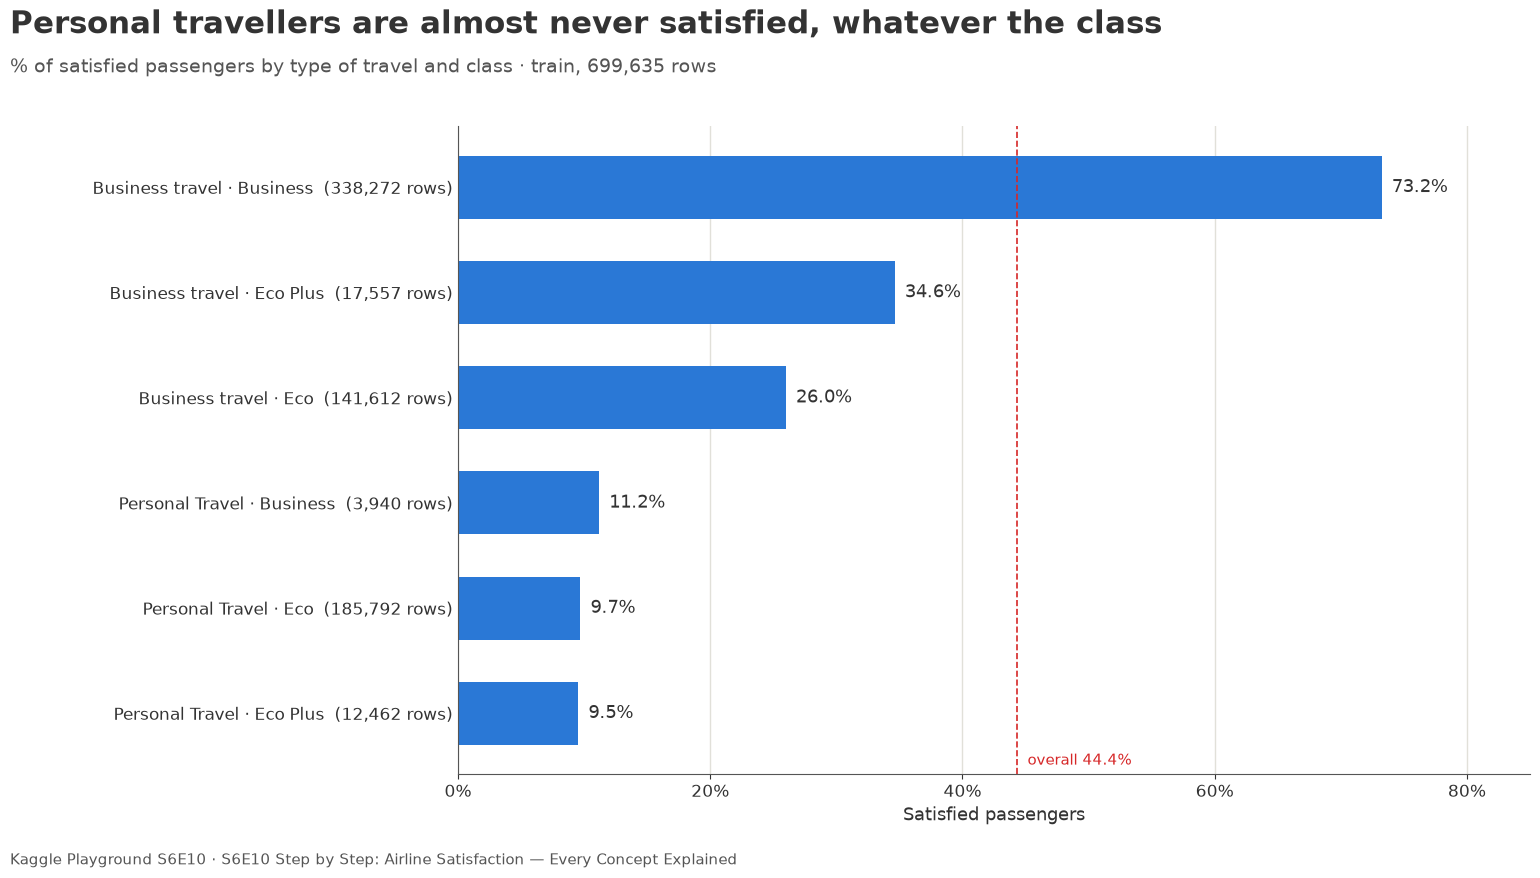

,Customer Type,Gender
Female,NaN,0.4380
Loyal Customer,0.4951,NaN
Male,NaN,0.4491
disloyal Customer,0.2009,NaN


In [7]:
g = (train.assign(y=y).groupby(["Type of Travel", "Class"], observed=True)["y"].agg(["mean", "size"])
     .reset_index().sort_values("mean"))
labels = [f"{t} · {c}  ({n:,} rows)" for t, c, n in zip(g["Type of Travel"], g["Class"], g["size"])]

fig, ax = shareable_figure(
    title="Personal travellers are almost never satisfied, whatever the class",
    subtitle=f"% of satisfied passengers by type of travel and class · train, {len(train):,} rows",
)
ax.barh(labels, g["mean"], color=BLUE, height=0.6)
for i, v in enumerate(g["mean"]):
    ax.text(v + 0.008, i, pct(v, 1), va="center", fontsize=13, color=DARK_GREY)
ax.axvline(BASE, ls="--", lw=1.2, color=ACCENT)
ax.text(BASE + 0.008, -0.45, f"overall {pct(BASE, 1)}", color=ACCENT, fontsize=11, va="center")
ax.set_xlim(0, 0.85)
ax.set_xticks(PCT_TICKS[:-1], [pct(v) for v in PCT_TICKS[:-1]])
ax.set_xlabel("Satisfied passengers")
ax.grid(axis="x", color=GRID, lw=1)
ax.tick_params(axis="y", length=0)
fig.subplots_adjust(left=0.30)
plt.show()

pd.DataFrame({c: pd.Series(y).groupby(train[c].to_numpy()).mean() for c in ["Customer Type", "Gender"]}).round(4)

The strongest split in the data is not a rating: it is **why the passenger travels**. On personal trips about 10% are
satisfied in all three classes. On business trips the class matters a lot: 26% in Eco, 35% in Eco Plus, 73% in
Business. This is an **interaction** — the effect of `Class` depends on `Type of Travel` — and it is another thing a
linear model cannot represent unless we build it by hand.

Loyal customers are satisfied 50% of the time against 20% for disloyal ones. Gender makes almost no difference
(44% and 45%).

## 3.3 Delays and missing values

In [8]:
pd.DataFrame({
    "missing in train": train[[DEP, ARR]].isna().sum(),
    "missing in test": test[[DEP, ARR]].isna().sum(),
    "share of zeros (train)": (train[[DEP, ARR]] == 0).mean().round(4),
    "mean minutes (train)": train[[DEP, ARR]].mean().round(2),
    "max minutes (train)": train[[DEP, ARR]].max(),
})

,missing in train,missing in test,share of zeros (train),mean minutes (train),max minutes (train)
Departure Delay in Minutes,0,0,0.9078,1.18,489.0
Arrival Delay in Minutes,292,130,0.9154,1.13,491.0


`Arrival Delay in Minutes` is missing in 292 train rows and 130 test rows (0.04%). More striking: **91% of flights
have no delay at all**, and the average delay is about one minute. Part 7 shows that the real survey looked very
different, and what that means.

> **Concept — missing values.** LightGBM handles a missing value natively: at every split it learns which side the
> missing rows should go to. Logistic regression cannot, so there we fill the gap with the median of the column
> (*imputation*).

## 3.4 Is the test set like the training set?

If the test passengers were different from the training ones (older, longer flights…), a model validated on train
would be judged on the wrong population.

> **Concept — adversarial validation.** Stack train and test, label each row with where it came from, and train a
> model to tell them apart. If that model scores an AUC of 0.5, it cannot distinguish them: both sets come from the
> same distribution, and a validation built on train is representative of test.

In [9]:
both = pd.concat([train[FEATURES], test[FEATURES]], ignore_index=True)
for c in CATEGORICAL:
    both[c] = both[c].astype("category")
is_test = np.r_[np.zeros(len(train)), np.ones(len(test))]
adv = np.zeros(len(both))
for tr, va in StratifiedKFold(3, shuffle=True, random_state=SEED).split(both, is_test):
    m = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, verbose=-1, random_state=SEED)
    m.fit(both.iloc[tr], is_test[tr])
    adv[va] = m.predict_proba(both.iloc[va])[:, 1]
print(f"adversarial validation AUC: {roc_auc_score(is_test, adv):.4f}  (0.5 = train and test are indistinguishable)")
del both

adversarial validation AUC: 0.4987  (0.5 = train and test are indistinguishable)


The adversarial AUC is 0.499: **train and test are indistinguishable**. A random split of train is therefore a fair
stand-in for the test set.

# Part 4 — Validation before modelling

This is the step most people skip, and the one that decides whether any later number means something.

> **Concept — overfitting.** A model *overfits* when it memorises the training data instead of learning patterns
> that generalise. Its score on the data it was trained on is then far better than on unseen data. So a score only
> means something if it is measured on rows the model has **not** seen.

> **Concept — K-fold cross-validation.** Split the training data into K parts (*folds*). Train on K−1 of them and
> score on the one left out; repeat K times so every row is used for validation exactly once. The K scores give a
> **mean** (how good the model is) and a **standard deviation** (how much that number moves by chance).

> **Concept — stratification.** Each fold keeps the same share of satisfied passengers as the whole dataset, so no
> fold is easier or harder than the others just because of how the rows were dealt.

## 4.1 The folds

In [10]:
folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(train, y))
for k, (tr_idx, va_idx) in enumerate(folds):
    print(f"fold {k}: train {len(tr_idx):,} rows | validation {len(va_idx):,} rows | "
          f"satisfied in validation {y[va_idx].mean():.4%}")

fold 0: train 559,708 rows | validation 139,927 rows | satisfied in validation 44.3567%
fold 1: train 559,708 rows | validation 139,927 rows | satisfied in validation 44.3574%
fold 2: train 559,708 rows | validation 139,927 rows | satisfied in validation 44.3574%
fold 3: train 559,708 rows | validation 139,927 rows | satisfied in validation 44.3574%
fold 4: train 559,708 rows | validation 139,927 rows | satisfied in validation 44.3574%


All models in this notebook use **these exact folds**, so their scores are directly comparable, fold by fold.

## 4.2 The CV must track the leaderboard

> **Concept — out-of-fold (OOF) predictions.** For each row, the prediction made by the one model that did *not* see
> it during training. Put together, they give one honest prediction per training row: we can score them, plot them,
> and study where the model is wrong.

The check that makes a CV *trustworthy*: **when CV goes up, the leaderboard should go up by a similar amount**.
If they disagree, fix the validation before tuning anything. We come back to this at the end of Part 6, once there
is a submission to compare.

A small helper runs any model through the folds and reports the per-fold score, mean ± std and the OOF score:

In [11]:
RESULTS = {}
FOLD_SCORES = {}
OOF = {}


def run_cv(name, fit_predict, keep_first_fold=False):
    # fit_predict(tr_idx, va_idx) -> (validation predictions, test predictions, info string, extras)
    oof, test_pred, scores = np.zeros(len(train)), np.zeros(len(test)), []
    start, first_fold = time.time(), None
    for k, (tr_idx, va_idx) in enumerate(folds):
        va_pred, te_pred, info, extras = fit_predict(tr_idx, va_idx)
        oof[va_idx] = va_pred
        test_pred += te_pred / N_FOLDS
        scores.append(score(y[va_idx], va_pred))
        if keep_first_fold and k == 0:
            first_fold = extras
        print(f"  fold {k}: {scores[-1]:.5f} {info}")
    RESULTS[name] = {"cv_mean": np.mean(scores), "cv_std": np.std(scores), "oof": score(y, oof)}
    FOLD_SCORES[name] = scores
    OOF[name] = oof
    print(f"{name}: CV {np.mean(scores):.5f} ± {np.std(scores):.5f} | OOF {RESULTS[name]['oof']:.5f} "
          f"| {time.time() - start:.0f}s")
    return test_pred, first_fold

# Part 5 — Model 1: logistic regression

We start with the simplest serious model, for two reasons: it gives a reference to measure everything else against,
and its weaknesses tell us what the data needs.

> **Concept — logistic regression.** It gives each feature a weight, adds everything up, and squashes the total into
> a probability between 0 and 1. It is *linear*: each extra unit of a feature moves the total by the same amount,
> whatever the value of the other features.

> **Concept — standardisation.** Rescaling each numeric feature to mean 0 and standard deviation 1. Distance goes up
> to 4,983 and a rating up to 5; without rescaling, the optimiser has a hard time and the regularisation penalises
> the features unevenly.

> **Concept — one-hot encoding.** Turning a categorical feature into one 0/1 column per category (`Class = Eco`,
> `Class = Business`…), so that a model that only understands numbers can use it.

In Part 3 we saw that the scores are **not monotonic**. So we run the model twice: with the 13 ratings as plain
numbers, and with the ratings **one-hot encoded**, which lets the model give each score (0, 1, 2…) its own weight.

In [12]:
def make_logreg(onehot_cols):
    scaled_cols = [c for c in NUMERIC if c not in onehot_cols]

    def fit_predict(tr_idx, va_idx):
        preprocess = ColumnTransformer([
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), scaled_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL + onehot_cols),
        ])
        model = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
        model.fit(train[FEATURES].iloc[tr_idx], y[tr_idx])
        return (model.predict_proba(train[FEATURES].iloc[va_idx])[:, 1],
                model.predict_proba(test[FEATURES])[:, 1], "", None)
    return fit_predict


test_pred_lr, _ = run_cv("Logistic regression (ratings as numbers)", make_logreg([]))
test_pred_lr_oh, _ = run_cv("Logistic regression (ratings one-hot)", make_logreg(RATINGS))

  fold 0: 0.92242 


  fold 1: 0.92142 


  fold 2: 0.92140 


  fold 3: 0.92127 


  fold 4: 0.92126 


...

  fold 1: 0.94778 


  fold 2: 0.94920 


  fold 3: 0.94848 


  fold 4: 0.94848 


Logistic regression (ratings one-hot): CV 0.94859 ± 0.00050 | OOF 0.94859 | 23s


With the ratings as plain numbers, logistic regression reaches a CV AUC of **0.92156 ± 0.00044**. One-hot encoding
the 13 ratings lifts it to **0.94859 ± 0.00050**: a gain of 0.027, some fifty times the standard deviation between
folds.

Same model, same information, a different *representation*. This is the heatmap of Part 3 turned into a number:
as plain numbers, the model must give wifi a single weight per point, and no single weight can say "0 is good, 1 to
3 are bad, 5 is excellent". With one column per score, it can.

What this model still cannot do is combine features — "Business class matters, but only on business trips". For
that we need a model that builds interactions by itself.

# Part 6 — Model 2: gradient-boosted trees with LightGBM

> **Concept — decision tree.** A sequence of yes/no questions on the features ("Online boarding ≥ 4?", "Type of
> Travel = Personal?") ending in a prediction. A tree handles non-monotonic scores and interactions naturally: it
> simply asks one more question.

> **Concept — gradient boosting.** Hundreds of small trees built one after another, each one trained to correct the
> errors left by the previous ones. The final prediction is the sum of all of them. `learning_rate` is how much each
> tree is allowed to correct: a small value needs more trees but generalises better.

> **Concept — early stopping.** We do not fix the number of trees. After each new tree we score the validation fold,
> and we stop when the score has not improved for 200 trees, keeping the best point. Too few trees underfit; too
> many overfit; the validation fold tells us where the turn is.

The parameters are deliberately plain — this is a baseline, not a tuned model.

In [13]:
for col in CATEGORICAL:
    levels = sorted(set(train[col]) | set(test[col]) | set(orig[col]))  # same codes everywhere
    train[col] = pd.Categorical(train[col], categories=levels)
    test[col] = pd.Categorical(test[col], categories=levels)
    orig[col] = pd.Categorical(orig[col], categories=levels)

LGB_PARAMS = {
    "objective": "binary",
    "metric": "auc",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "min_child_samples": 100,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "seed": SEED,
    "verbose": -1,
}


def make_lgbm(get_frames):
    # get_frames(tr_idx, va_idx) -> (X_tr, X_va, X_te) with the columns to use
    def fit_predict(tr_idx, va_idx):
        X_tr, X_va, X_te = get_frames(tr_idx, va_idx)
        booster = lgb.train(
            LGB_PARAMS,
            lgb.Dataset(X_tr, y[tr_idx]),
            num_boost_round=5000,
            valid_sets=[lgb.Dataset(X_va, y[va_idx])],
            callbacks=[lgb.early_stopping(200, verbose=False)],
        )
        return (booster.predict(X_va), booster.predict(X_te),
                f"(trees: {booster.best_iteration})", (booster, X_va))
    return fit_predict


def raw_frames(tr_idx, va_idx):
    return train[FEATURES].iloc[tr_idx], train[FEATURES].iloc[va_idx], test[FEATURES]


RAW = "LightGBM (raw features)"
test_pred_raw, (raw_booster, raw_X_va) = run_cv(RAW, make_lgbm(raw_frames), keep_first_fold=True)

  fold 0: 0.95899 (trees: 1021)


  fold 1: 0.95763 (trees: 1186)


  fold 2: 0.95950 (trees: 1015)


  fold 3: 0.95898 (trees: 1249)


  fold 4: 0.95899 (trees: 784)


LightGBM (raw features): CV 0.95882 ± 0.00063 | OOF 0.95881 | 271s


LightGBM on the 21 raw features reaches a CV AUC of **0.95882 ± 0.00063** — 0.010 above the best logistic
regression, with no scaling, no one-hot encoding and the missing values left as they are.

Two things to read in the output:

- **The folds agree.** They range from 0.95763 to 0.95950. The standard deviation, 0.0006, is our yardstick from now
  on: an improvement smaller than that cannot be told apart from the luck of the split.
- **Early stopping chose the size.** Each fold stopped somewhere between 784 and 1,249 trees, well below the limit
  of 5,000.

## 6.1 Where is the model wrong?

An AUC of 0.959 still leaves errors. The OOF predictions let us look at them: we group the training passengers by
the probability the model gave them, and split each group by their true label.

rows predicted below 10% or above 90%: 84.0%
errors with a 0.5 cut-off: 51,659 (7.38% of train)
of those, the model was above 90% on the wrong side: 25,048 (48.5% of the errors)


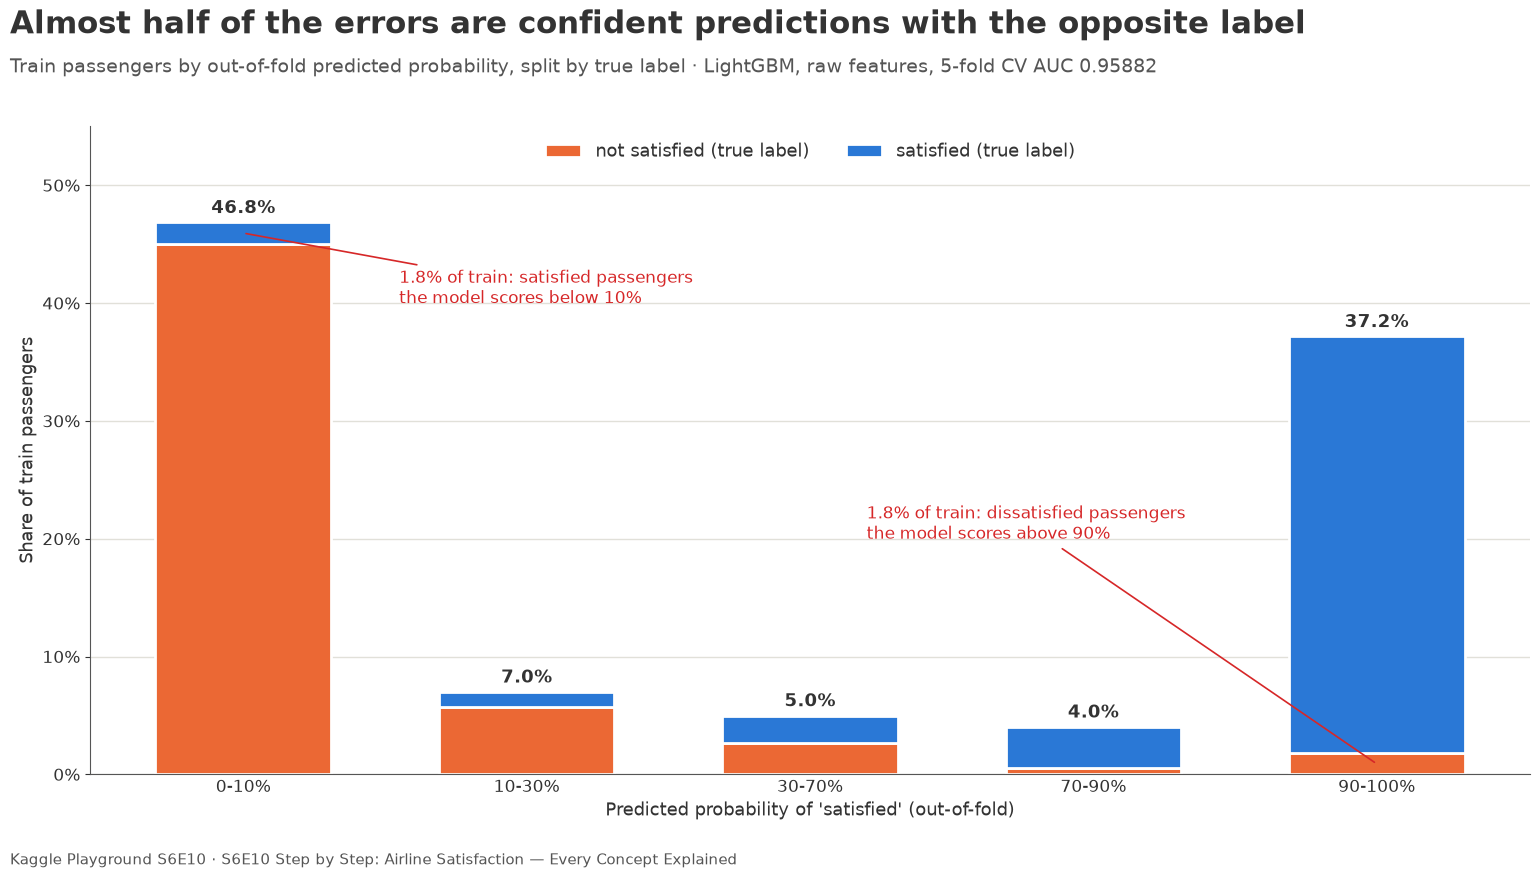

In [14]:
oof = OOF[RAW]
bands = ["0-10%", "10-30%", "30-70%", "70-90%", "90-100%"]
band = pd.cut(oof, [0, 0.1, 0.3, 0.7, 0.9, 1.0], labels=bands, include_lowest=True)
table = pd.crosstab(band, y).reindex(bands) / len(oof)  # columns: 0 = not satisfied, 1 = satisfied
errors = (oof > 0.5) != y
confident_wrong = ((oof > 0.9) & (y == 0)) | ((oof < 0.1) & (y == 1))
print(f"rows predicted below 10% or above 90%: {((oof < 0.1) | (oof > 0.9)).mean():.1%}")
print(f"errors with a 0.5 cut-off: {errors.sum():,} ({errors.mean():.2%} of train)")
print(f"of those, the model was above 90% on the wrong side: {confident_wrong.sum():,} "
      f"({confident_wrong.sum() / errors.sum():.1%} of the errors)")

fig, ax = shareable_figure(
    title="Almost half of the errors are confident predictions with the opposite label",
    subtitle=f"Train passengers by out-of-fold predicted probability, split by true label · LightGBM, raw features, "
             f"{N_FOLDS}-fold CV AUC {RESULTS[RAW]['cv_mean']:.5f}",
)
xs = np.arange(len(bands))
ax.bar(xs, table[0], 0.62, color=ORANGE, label="not satisfied (true label)", edgecolor="white", linewidth=2)
ax.bar(xs, table[1], 0.62, bottom=table[0], color=BLUE, label="satisfied (true label)", edgecolor="white",
       linewidth=2)
for xi, total in enumerate(table.sum(axis=1)):
    ax.text(xi, total + 0.008, pct(total, 1), ha="center", fontsize=13, color=DARK_GREY, fontweight="bold")
annotate(ax, f"{pct(table.loc['0-10%', 1], 1)} of train: satisfied passengers\nthe model scores below 10%",
         xy=(0.0, table.loc["0-10%"].sum() - table.loc["0-10%", 1] / 2), xytext=(0.55, 0.40))
annotate(ax, f"{pct(table.loc['90-100%', 0], 1)} of train: dissatisfied passengers\nthe model scores above 90%",
         xy=(4.0, table.loc["90-100%", 0] / 2), xytext=(2.2, 0.20))
ax.set_xticks(xs, bands)
ax.set_ylim(0, 0.55)
ax.set_yticks(np.arange(0, 0.51, 0.1), [pct(v) for v in np.arange(0, 0.51, 0.1)])
ax.set_xlabel("Predicted probability of 'satisfied' (out-of-fold)")
ax.set_ylabel("Share of train passengers")
ax.grid(axis="y", color=GRID, lw=1)
ax.tick_params(axis="x", length=0)
ax.legend(loc="upper center", frameon=False, fontsize=13, labelcolor=DARK_GREY, ncols=2)
plt.show()

The model is **sure** about 84% of the passengers (probability below 10% or above 90%), and for them it is almost
always right. But inside each of those two sure groups there is a slice of about 1.8% of train whose label is the
opposite one. Together they are **48.5% of all the errors**.

These are not passengers the model hesitates about. They are passengers whose answers look exactly like those of
a satisfied (or dissatisfied) customer, with the other label attached. Part 7 gives evidence that this comes from
the synthetic generator — and if the label was partly drawn at random, **no model can predict it**. This puts a
ceiling on the AUC, and it means that from here on improvements will be measured in the third and fourth decimal.

## 6.2 Does the CV track the leaderboard?

The test predictions of this model (the average of the five fold models) were submitted to the competition:

| Model | CV AUC | Public LB | Difference |
|---|---|---|---|
| LightGBM, raw features | 0.95882 ± 0.00063 | 0.95848 | 0.00034 |

The difference between CV and public leaderboard is 0.00034, **smaller than one standard deviation between folds**
(0.00063). Together with the adversarial validation of Part 3, this says the CV can be trusted: what improves
locally should improve on the leaderboard too. The public leaderboard only uses part of the test set, so from here
on the CV — computed on all 699,635 training rows — is the number we follow.

# Part 7 — Feature engineering: what the original dataset reveals

The data was generated from a real survey with 129,880 passengers. A generator is never perfect: comparing its
output with the real thing shows **what it copied, what it distorted, and what it could not learn** — and each of
the three has a consequence for the model.

The central idea of this part comes from the community. In the previous episode (S6E9), Marc Maldonado Lorca
([discussion](https://www.kaggle.com/competitions/playground-series-s6e9/discussion/742385), crediting Hayashi,
Mamarin, megayak and Naji) showed that the generator had **copied exact values** of a numeric column from the
original data, and that those exact values carried information about the label. Here we ask the same question of a
new dataset.

## 7.1 How similar are the synthetic data and the original?

In [15]:
y_orig = orig[TARGET].astype(int).to_numpy()
print(f"satisfied: original {y_orig.mean():.2%} | train {BASE:.2%}")

pd.DataFrame({
    "mean (original)": orig[[DIST, DEP, ARR, "Age"]].mean(),
    "mean (train)": train[[DIST, DEP, ARR, "Age"]].mean(),
    "% zeros (original)": (orig[[DIST, DEP, ARR, "Age"]] == 0).mean() * 100,
    "% zeros (train)": (train[[DIST, DEP, ARR, "Age"]] == 0).mean() * 100,
    "max (original)": orig[[DIST, DEP, ARR, "Age"]].max(),
    "max (train)": train[[DIST, DEP, ARR, "Age"]].max(),
}).round(2)

satisfied: original 43.45% | train 44.36%


,mean (original),mean (train),% zeros (original),% zeros (train),max (original),max (train)
Flight Distance,1190.32,1353.78,0.00,0.00,4983.0,4983.0
Departure Delay in Minutes,14.71,1.18,56.48,90.78,1592.0,489.0
Arrival Delay in Minutes,15.09,1.13,56.02,91.54,1584.0,491.0
Age,39.43,39.00,0.00,0.00,85.0,85.0


Same columns, almost the same satisfaction rate (43.4% in the original, 44.4% in train), similar ages and distances.
One thing is very different: **the delays**. In the real survey the average departure delay is 14.7 minutes and 56%
of flights leave on time; in the synthetic data the average is 1.2 minutes and 91% leave on time. The generator
turned most delays into zeros. This explains why the delay columns will matter so little, and it is a warning
against simply appending the original rows to the training set: in those two columns they do not look alike.

## 7.2 Did the generator copy exact values?

A generator that truly *invented* a flight distance would produce numbers all over the range. Let us check whether
the distances in train are new numbers or numbers taken from the original.

In [16]:
orig_values = set(orig[DIST])
all_integers = np.arange(orig[DIST].min(), orig[DIST].max() + 1)
unused = set(all_integers) - orig_values
print(f"the original uses {len(orig_values):,} of the {len(all_integers):,} integers in its range "
      f"({len(orig_values) / len(all_integers):.1%}); {len(unused):,} integers never appear")
print(f"train rows whose distance is one of those unused integers: {train[DIST].isin(unused).sum():,} "
      f"of {len(train):,}")
print(f"test rows whose distance is one of those unused integers:  {test[DIST].isin(unused).sum():,} "
      f"of {len(test):,}")

both_full = train[FEATURES].merge(orig[FEATURES].drop_duplicates(), on=FEATURES, how="inner")
print(f"train rows identical to an original row on all {len(FEATURES)} features: {len(both_full):,}")

the original uses 3,821 of the 4,953 integers in its range (77.1%); 1,132 integers never appear
train rows whose distance is one of those unused integers: 4 of 699,635
test rows whose distance is one of those unused integers:  1 of 299,844


train rows identical to an original row on all 21 features: 17


The original leaves 1,132 integers of its distance range unused (23% of them). If the generator invented distances,
a good share of the synthetic rows would land on one of those gaps. **Only 4 rows out of 699,635 do.** The generator
did not invent distances: it picked them from the list of distances that exist in the original.

It did not copy whole passengers, though: only 17 train rows match an original row on all 21 features. So there is
no shortcut of the kind "look the passenger up in the original".

## 7.3 Does the exact distance carry information?

A flight distance of exactly 594 miles is not just "a medium-short flight": it is very likely **one specific
route**, with its own airports and its own mix of passengers. If so, each exact distance should have its own
satisfaction rate, different from that of its neighbours. (The data has no route column, so this is an
interpretation; what we can measure is the rate per distance.)

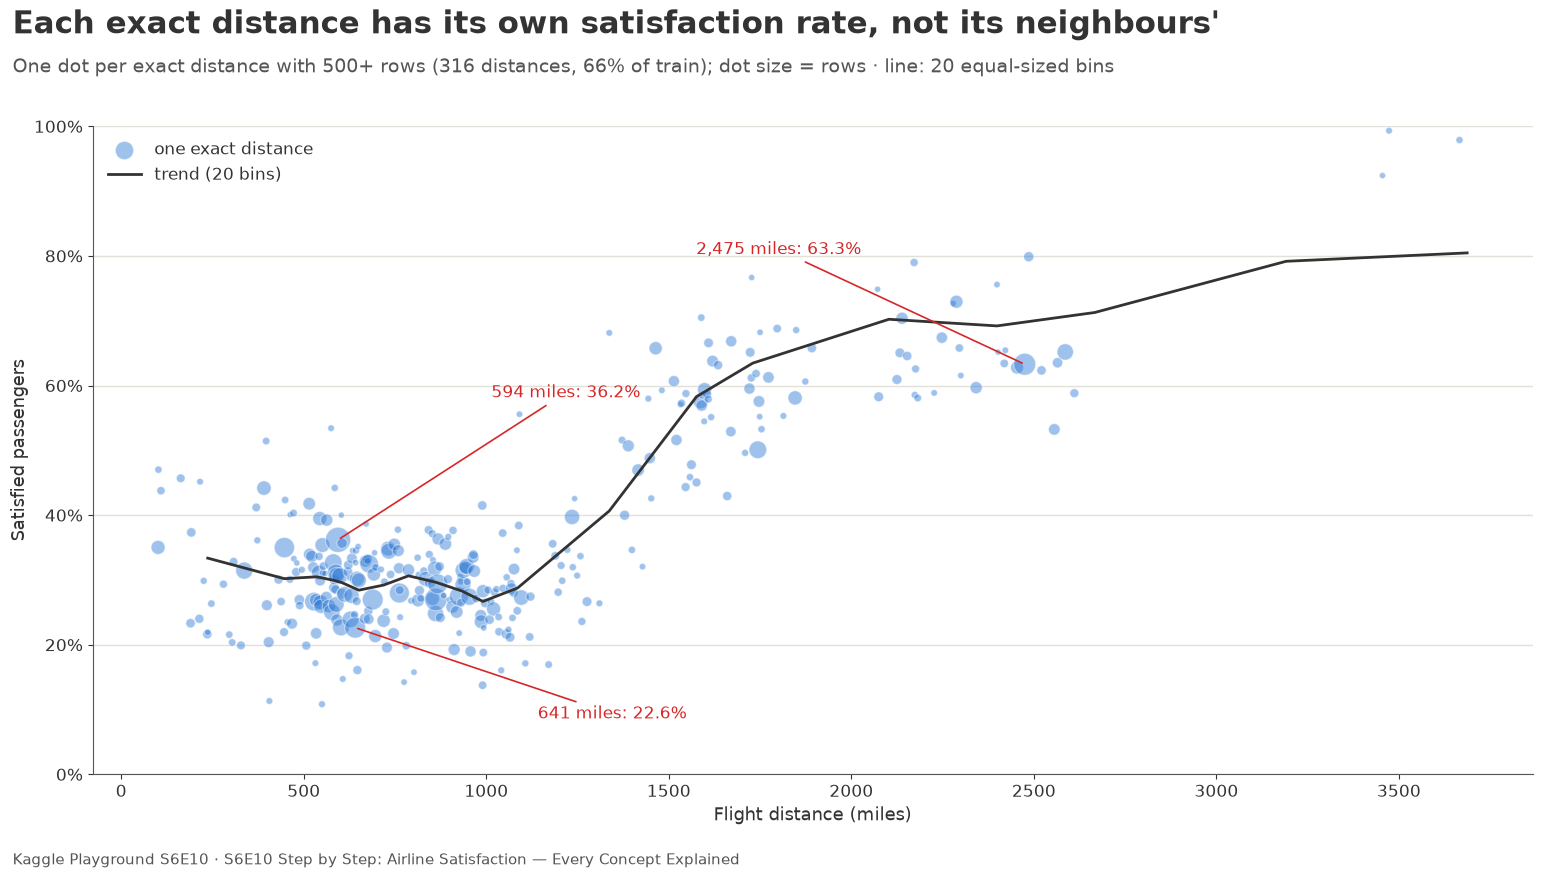

In [17]:
by_dist = pd.DataFrame({
    "rate_train": pd.Series(y).groupby(train[DIST].to_numpy()).mean(), "n_train": train[DIST].value_counts(),
    "rate_orig": pd.Series(y_orig).groupby(orig[DIST].to_numpy()).mean(), "n_orig": orig[DIST].value_counts(),
})
frequent = by_dist[by_dist["n_train"] >= 500]
bins20 = pd.qcut(train[DIST], 20, duplicates="drop")
smooth = train.assign(y=y).groupby(bins20, observed=True).agg(x=(DIST, "median"), rate=("y", "mean"))

fig, ax = shareable_figure(
    title="Each exact distance has its own satisfaction rate, not its neighbours'",
    subtitle=f"One dot per exact distance with 500+ rows ({len(frequent):,} distances, "
             f"{pct(frequent['n_train'].sum() / len(train))} of train); dot size = rows · line: 20 equal-sized bins",
)
ax.scatter(frequent.index, frequent["rate_train"], s=frequent["n_train"] / 25, color=BLUE, alpha=0.45,
           edgecolors="white", linewidths=0.8, label="one exact distance")
ax.plot(smooth["x"], smooth["rate"], color=DARK_GREY, lw=2, label="trend (20 bins)")
for d, dx, dy in [(594, 420, 0.22), (641, 500, -0.14), (2475, -900, 0.17)]:
    v = frequent.loc[d, "rate_train"]
    annotate(ax, f"{d:,} miles: {pct(v, 1)}", xy=(d, v), xytext=(d + dx, v + dy))
ax.set_xlabel("Flight distance (miles)")
ax.set_ylabel("Satisfied passengers")
ax.set_ylim(0, 1)
ax.set_yticks(PCT_TICKS, [pct(v) for v in PCT_TICKS])
ax.grid(axis="y", color=GRID, lw=1)
ax.legend(loc="upper left", frameon=False, fontsize=12, labelcolor=DARK_GREY)
plt.show()

The line is what a model sees if it only uses distance as a *magnitude*: satisfaction rises with distance. The dots
tell a different story. Flights of 594 miles have 36.2% satisfied passengers and flights of 641 miles have 22.6%,
with thousands of rows behind each number. Forty-seven extra miles do not explain a 14-point gap; a different route
does.

Is this real, or noise that happens to look like a pattern? The original dataset can answer: if each distance has a
"personality", it should be the same one in the real survey.

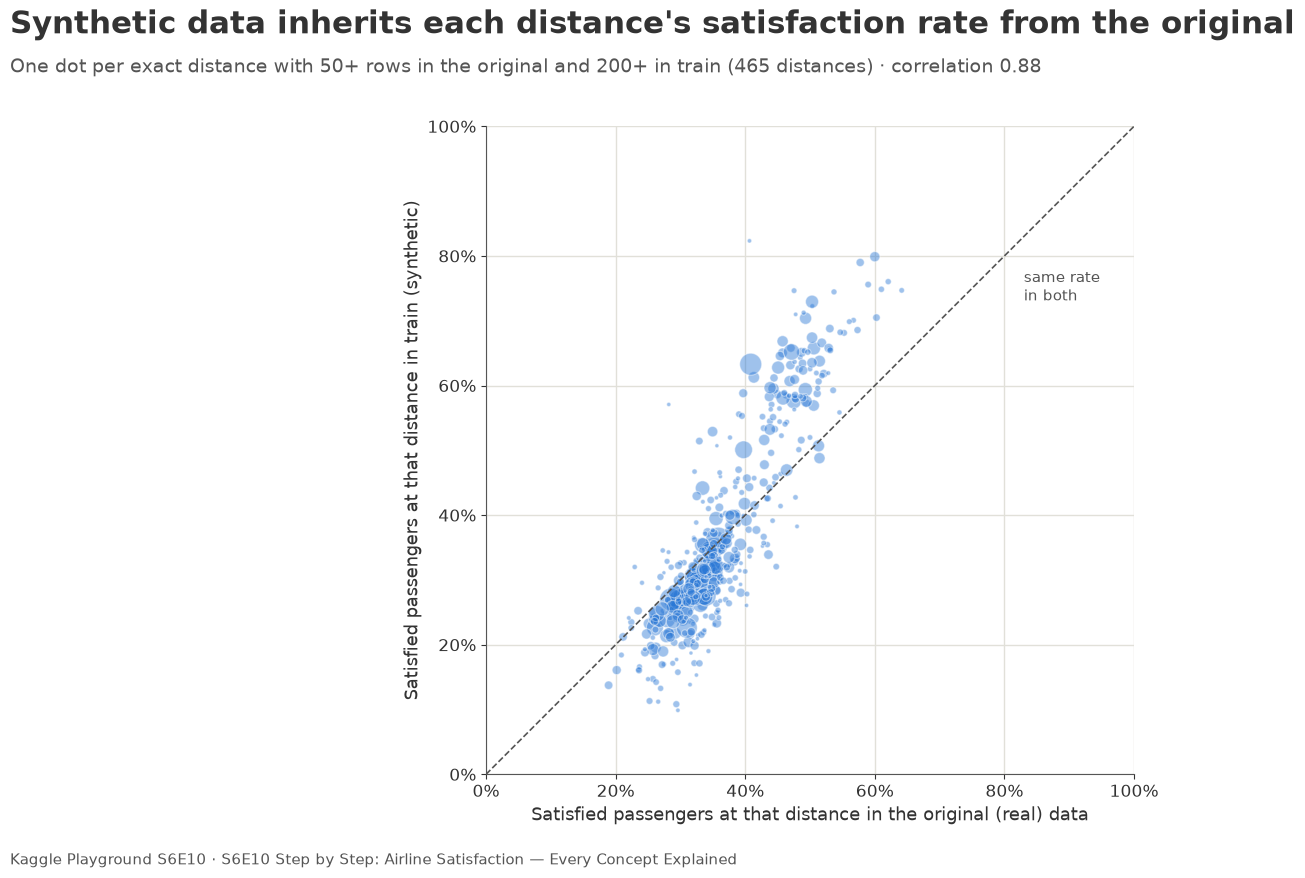

In [18]:
common = by_dist.dropna()
big = common[(common["n_orig"] >= 50) & (common["n_train"] >= 200)]
corr = big[["rate_orig", "rate_train"]].corr().iloc[0, 1]

fig, ax = shareable_figure(
    title="Synthetic data inherits each distance's satisfaction rate from the original",
    subtitle=f"One dot per exact distance with 50+ rows in the original and 200+ in train ({len(big):,} distances) · "
             f"correlation {corr:.2f}",
)
ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color=MID_GREY)
ax.scatter(big["rate_orig"], big["rate_train"], s=big["n_train"] / 25, color=BLUE, alpha=0.45,
           edgecolors="white", linewidths=0.8)
ax.text(0.83, 0.78, "same rate\nin both", color=MID_GREY, fontsize=11, ha="left", va="top")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks(PCT_TICKS, [pct(v) for v in PCT_TICKS])
ax.set_yticks(PCT_TICKS, [pct(v) for v in PCT_TICKS])
ax.set_xlabel("Satisfied passengers at that distance in the original (real) data")
ax.set_ylabel("Satisfied passengers at that distance in train (synthetic)")
ax.grid(color=GRID, lw=1)
ax.set_aspect("equal", adjustable="box")
plt.show()

The correlation is 0.88: a distance with many satisfied passengers in the real survey also has many in the synthetic
data. The pattern is not noise — the generator learned it from the original. (It also exaggerated it: above 40% the
dots sit over the diagonal.)

## 7.4 Turning the exact distance into a feature

> **Concept — target encoding.** Replace a value by the average target of the training rows that share it: here,
> "the satisfaction rate of the passengers who flew exactly this distance". It turns thousands of distinct values
> into one number the model can use directly.

> **Concept — leakage.** If a row's own label is used to compute its own feature, the model learns to read the
> answer from the feature. The CV score soars and the leaderboard does not follow. Target encoding is the classic
> way to do this by accident.

> **Concept — smoothing.** A distance with 3 rows gives a very unreliable rate. We pull each rate towards the
> overall rate, strongly when there are few rows and barely at all when there are thousands:
> `(sum of targets + 20 × overall rate) / (rows + 20)`.

First, a quick test with **distance alone**, always out-of-fold: is the exact value better than a binned one?

In [19]:
SMOOTHING = 20


def smoothed_rate(keys, labels):
    """Satisfaction rate per key, pulled towards the overall rate of those rows."""
    prior = labels.mean()
    g = pd.DataFrame({"k": keys, "y": labels}).groupby("k")["y"].agg(["sum", "count"])
    return (g["sum"] + SMOOTHING * prior) / (g["count"] + SMOOTHING), prior


def te_oof(keys):
    """Out-of-fold target encoding of `keys` (numpy array) with the notebook folds."""
    out = np.zeros(len(train))
    for tr_idx, va_idx in folds:
        enc, prior = smoothed_rate(keys[tr_idx], y[tr_idx])
        out[va_idx] = pd.Series(keys[va_idx]).map(enc).fillna(prior).to_numpy()
    return out


dist = train[DIST].to_numpy()
rows = {"raw distance (as a magnitude)": score(y, dist)}
for q in [20, 100, 500]:
    binned = pd.qcut(train[DIST], q, duplicates="drop").cat.codes.to_numpy()
    rows[f"target encoding of {len(np.unique(binned))} quantile bins"] = score(y, te_oof(binned))
rows[f"target encoding of the exact value ({train[DIST].nunique():,} values)"] = score(y, te_oof(dist))
pd.Series(rows).round(5).to_frame("OOF AUC using distance alone")

,OOF AUC using distance alone
raw distance (as a magnitude),0.69559
target encoding of 20 quantile bins,0.70580
target encoding of 100 quantile bins,0.71394
target encoding of 405 quantile bins,0.72510
"target encoding of the exact value (3,474 values)",0.74131


With distance alone, the exact value reaches 0.741 against 0.725 for 405 bins and 0.696 for the raw number. The
finer we cut, the better — and the exact value is the finest cut there is.

**One new column, not thousands.** Target encoding does not create one column per distance. It adds a **single
numeric column**, which we call `dist_te`, holding the satisfaction rate of the passenger's exact distance. The
model goes from 21 features to 22:

| Passenger | `Flight Distance` | `dist_te` (new column) |
|---|---|---|
| A | 594 | 0.362 |
| B | 641 | 0.226 |
| C | 594 | 0.362 |

Passengers A and C fly the same distance, so they get the same value. `Flight Distance` itself stays where it was,
as a number. Once computed, `dist_te` is used like any other numeric feature: the trees look for cuts such as
"is the rate of this distance above 0.40?". (The values in the table are the rates over the whole of train, the ones
annotated in the chart of 7.3. In the real pipeline each passenger gets a rate computed without their own label, so
the numbers differ slightly from fold to fold.)

Why not **one-hot encode** the distance instead, as we did with the ratings in Part 5? Because there are 3,474
distinct distances: that would be 3,474 columns of zeros and ones, most of them almost empty, and a tree would have
to ask about them one distance at a time. With a single ordered column, one question separates all the "good"
distances from all the "bad" ones. (This is the usual reasoning; the one-hot version is not measured in this
notebook.)

A single-feature test is only a hint. The real question is whether `dist_te` adds something **to a model that
already has the other 21 features**. To answer without leakage, the encoding is computed inside each fold:

- **validation and test rows** get the rates computed on that fold's training rows;
- **training rows** get rates computed with *inner* folds, so that no row ever sees its own label.

In [20]:
def te_frames(tr_idx, va_idx):
    te_tr = np.zeros(len(tr_idx))
    inner = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(tr_idx, y[tr_idx])
    for a, b in inner:  # positions inside tr_idx
        enc, prior = smoothed_rate(dist[tr_idx[a]], y[tr_idx[a]])
        te_tr[b] = pd.Series(dist[tr_idx[b]]).map(enc).fillna(prior).to_numpy()
    enc, prior = smoothed_rate(dist[tr_idx], y[tr_idx])
    X_tr = train[FEATURES].iloc[tr_idx].assign(dist_te=te_tr)
    X_va = train[FEATURES].iloc[va_idx].assign(dist_te=train[DIST].iloc[va_idx].map(enc).fillna(prior).to_numpy())
    X_te = test[FEATURES].assign(dist_te=test[DIST].map(enc).fillna(prior).to_numpy())
    return X_tr, X_va, X_te


TE = "LightGBM + exact-distance target encoding"
test_pred_te, (te_booster, te_X_va) = run_cv(TE, make_lgbm(te_frames), keep_first_fold=True)
delta = np.array(FOLD_SCORES[TE]) - np.array(FOLD_SCORES[RAW])
print("gain per fold over the raw-feature model:", np.round(delta, 5), "| mean", round(delta.mean(), 5))

  fold 0: 0.96030 (trees: 1045)


  fold 1: 0.95902 (trees: 862)


  fold 2: 0.96059 (trees: 1070)


  fold 3: 0.96022 (trees: 1125)


  fold 4: 0.96030 (trees: 620)


LightGBM + exact-distance target encoding: CV 0.96009 ± 0.00055 | OOF 0.96008 | 242s
gain per fold over the raw-feature model: [0.00131 0.00138 0.00109 0.00124 0.0013 ] | mean 0.00127


With the encoded distance the CV AUC goes from 0.95882 to **0.96009 ± 0.00055**: a gain of **0.00127**. It is small
in absolute terms, but it is twice the standard deviation between folds and, more importantly, **every one of the
five folds improves**, by between 0.00109 and 0.00138. A gain that shows up in all folds with the same size is not
luck.

Why could LightGBM not find this by itself, having `Flight Distance` all along? A tree uses a numeric feature
through thresholds ("distance ≤ 617?"). To isolate the passengers of exactly 594 miles from their neighbours it needs
two cuts, and it would have to do that for thousands of distances, each with a few hundred rows. The target encoding
hands it the same information as a single ordered number.

**And the leaderboard agrees.** This is the model behind the `submission.csv` written at the end of the notebook.
Submitted, it scores 0.95973 on the public leaderboard, against 0.95848 for the raw-feature model:

| Model | CV AUC | Public LB |
|---|---|---|
| LightGBM, raw features | 0.95882 | 0.95848 |
| LightGBM + exact-distance target encoding | 0.96009 | 0.95973 |
| **Gain** | **+0.00127** | **+0.00125** |

The CV promised +0.00127 and the leaderboard delivered +0.00125. This is what Part 4 was for: a validation that
tracks the leaderboard lets us decide what to keep without spending submissions.

## 7.5 How much noise did the generator add?

One last use of the original dataset. We train the same LightGBM **on the original data only** and ask it two
things: how well does it predict the original (cross-validated), and how well does it predict our synthetic train?

In [21]:
orig_model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
orig_oof = np.zeros(len(orig))
for tr, va in StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(orig, y_orig):
    m = lgb.LGBMClassifier(**orig_model.get_params()).fit(orig[FEATURES].iloc[tr], y_orig[tr])
    orig_oof[va] = m.predict_proba(orig[FEATURES].iloc[va])[:, 1]
orig_model.fit(orig[FEATURES], y_orig)
on_train = orig_model.predict_proba(train[FEATURES])[:, 1]
print(f"trained on the original, scored on the original (5-fold CV): {score(y_orig, orig_oof):.5f}")
print(f"trained on the original, scored on the synthetic train:      {score(y, on_train):.5f}")
print(f"trained on the synthetic train, scored on it (5-fold CV):    {RESULTS[RAW]['cv_mean']:.5f}")

trained on the original, scored on the original (5-fold CV): 0.99501


trained on the original, scored on the synthetic train:      0.95437
trained on the synthetic train, scored on it (5-fold CV):    0.95882


In the real survey the problem is almost solved: an AUC of 0.995. The **same model**, applied to the synthetic
passengers, drops to 0.954 — and training on 700,000 synthetic rows instead of 130,000 real ones only lifts it to
0.959.

So the rules that link the answers to satisfaction are essentially the same in both datasets (a model that never saw
a synthetic row gets 0.954 on them), but the synthetic labels follow those rules less faithfully. This is the
evidence behind Part 6.1: the confident errors are, most likely, labels the generator did not attach consistently.
No amount of tuning recovers them.

# Part 8 — Interpreting the model with SHAP

A LightGBM model is a thousand trees added together; nobody can read it. SHAP answers one question about it:
**why did the model give *this* passenger *this* score?**

> **Concept — SHAP values.** Think of a prediction as an invoice. There is a base amount — the average prediction
> for everybody — and then each piece of information about the passenger adds to it or takes away from it. The SHAP
> values are the lines of that invoice: **one push per feature**, up (towards "satisfied") or down (towards "not
> satisfied"). Added to the base amount, they give exactly the model's output for that passenger.

Two things to know before reading the numbers:

- **The sign is the direction and the size is the strength.** A push of +2.5 is a strong push towards "satisfied";
  −0.2 is a gentle push the other way.
- **The pushes are not percentages.** They live on the model's internal scale (called *log-odds*), where pushes can
  simply be added. Only the final total is converted into a probability.

LightGBM computes SHAP values natively with `pred_contrib=True` — no extra library needed. We use the fold-0 model of
the best pipeline and 20,000 passengers it did not see during training.

In [22]:
final_booster, final_X_va = te_booster, te_X_va
sample = final_X_va.sample(min(20_000, len(final_X_va)), random_state=SEED)
contrib = final_booster.predict(sample, pred_contrib=True)
shap_values = pd.DataFrame(contrib[:, :-1], columns=sample.columns, index=sample.index)
expected_value = contrib[0, -1]  # the base amount, the same for everybody

raw = final_booster.predict(sample, raw_score=True)
print(f"{shap_values.shape[0]:,} passengers x {shap_values.shape[1]} features, one push each")
print("largest gap between 'base + sum of pushes' and the model's output:",
      float(np.abs(expected_value + shap_values.sum(axis=1) - raw).max()))

20,000 passengers x 22 features, one push each
largest gap between 'base + sum of pushes' and the model's output: 4.4853010194856324e-14


The gap is zero up to rounding error: for every one of the 20,000 passengers, the base amount plus the 22 pushes
gives exactly what the model outputs. The invoice always adds up.

## 8.1 One passenger, line by line

To see an invoice in full we pick, among those 20,000 passengers, the one where **the features disagree the most**:
strong pushes up and strong pushes down at the same time.

In [23]:
up = shap_values.clip(lower=0).sum(axis=1)       # total push towards "satisfied"
down = -shap_values.clip(upper=0).sum(axis=1)    # total push towards "not satisfied"
who = np.minimum(up, down).idxmax()               # the passenger with the biggest tug of war
pushes = shap_values.loc[who]
total = expected_value + pushes.sum()

print(f"passenger id {train.loc[who, 'id']} · true label: {'satisfied' if y[who] else 'not satisfied'}")
print(f"base amount (average passenger)       {expected_value:+.3f}")
print(f"pushes towards 'satisfied'            {up[who]:+.3f}")
print(f"pushes towards 'not satisfied'        {-down[who]:+.3f}")
print(f"total = the model's raw output        {total:+.3f}")
print(f"converted into a probability          {1 / (1 + np.exp(-total)):.1%}")
print(f"what the model predicts for this row  {final_booster.predict(sample.loc[[who]])[0]:.1%}")

values = sample.loc[who].astype(object)
values["dist_te"] = round(values["dist_te"], 3)
pd.DataFrame({"this passenger's value": values, "push": pushes.round(3)}).sort_values("push", ascending=False)

passenger id 657021 · true label: satisfied
base amount (average passenger)       -0.427
pushes towards 'satisfied'            +3.574
pushes towards 'not satisfied'        -3.711
total = the model's raw output        -0.565
converted into a probability          36.3%
what the model predicts for this row  36.3%


,this passenger's value,push
Inflight wifi service,5,2.783
Baggage handling,5,0.192
Customer Type,Loyal Customer,0.176
On-board service,5,0.173
Age,49,0.120
dist_te,0.501,0.083
Checkin service,4,0.031
Food and drink,4,0.013
Inflight entertainment,5,0.004
Gender,Female,-0.011


The passenger is a 49-year-old loyal customer on a **personal trip in Eco**, who gave the wifi a **5** and the online
boarding a **3**. Reading the invoice from the top:

- **The base amount is −0.427.** Before knowing anything, the model leans slightly towards "not satisfied", which is
  what we expect when 44% of passengers are satisfied.
- **One line dominates the pushes up: wifi = 5, with +2.783.** On its own it would make the model almost sure this
  passenger is satisfied. The next ones are far behind: baggage handling 5 (+0.192), loyal customer (+0.176).
- **Several lines push down:** personal travel (−1.395), online boarding scored 3 (−0.749), the flight distance
  (−0.416), online booking scored 1 (−0.334) and an arrival delay of 18 minutes (−0.306).
- **Many lines are almost zero:** gender (−0.011), cleanliness (−0.012), gate location (−0.012). The model knows
  these values and does nothing with them.

The pushes up add to +3.574 and the pushes down to −3.711: they nearly cancel. Base plus pushes gives −0.565, which
converted into a probability is **36.3%** — exactly what the model predicts for this row.

This passenger was in fact satisfied, so the model leaned the wrong way. But look at how: with 36%, not with 2%.
The model had good reasons on both sides and said so. This is what an honest "I am not sure" looks like, and it is
the opposite of the confident errors of Part 6.1.

## 8.2 Which features matter most, over all passengers?

One invoice explains one passenger. To describe the model as a whole we average the **size** of each feature's push
over the 20,000 passengers, ignoring its direction.

In [24]:
importance = shap_values.abs().mean().sort_values(ascending=False)
(importance / importance.sum()).round(4).to_frame("share of the total push")

,share of the total push
Online boarding,0.1766
Type of Travel,0.1526
Inflight wifi service,0.1280
Customer Type,0.0918
Class,0.0822
dist_te,0.0670
Flight Distance,0.0427
Baggage handling,0.0363
Checkin service,0.0309
Seat comfort,0.0275


The table ranks the features by how much they move the predictions on average:

- **`Online boarding` (17.7%), `Type of Travel` (15.3%) and `Inflight wifi service` (12.8%)** lead, followed by
  `Customer Type` (9.2%) and `Class` (8.2%). These are the same features the EDA pointed at.
- **The encoded distance `dist_te` is sixth (6.7%)**, ahead of the raw `Flight Distance` (4.3%). The feature we
  built in Part 7 is not a rounding detail: the model leans on it more than on any single rating other than online
  boarding and wifi.
- **The two delay columns add up to about 1%**, as expected after seeing in Part 7 that the generator erased most
  delays. `Gender` is at 0.4%.

A ranking says *how much* a feature matters, not *in which direction*. For that we take the two ratings at the top
and average the push of each score, this time keeping the sign.

## 8.3 In which direction? The two top ratings, score by score

        mean SHAP                       rows in the sample  \
  Online boarding Inflight wifi service    Online boarding   
0           0.008                 2.563                248   
1          -0.828                -0.229               1572   
2          -0.912                -0.342               3465   
3          -1.015                -0.362               4236   
4           0.582                 0.589               6084   
5           1.045                 1.937               4395   

                         
  Inflight wifi service  
0                   366  
1                  3041  
2                  5382  
3                  5231  
4                  3740  
5                  2240  


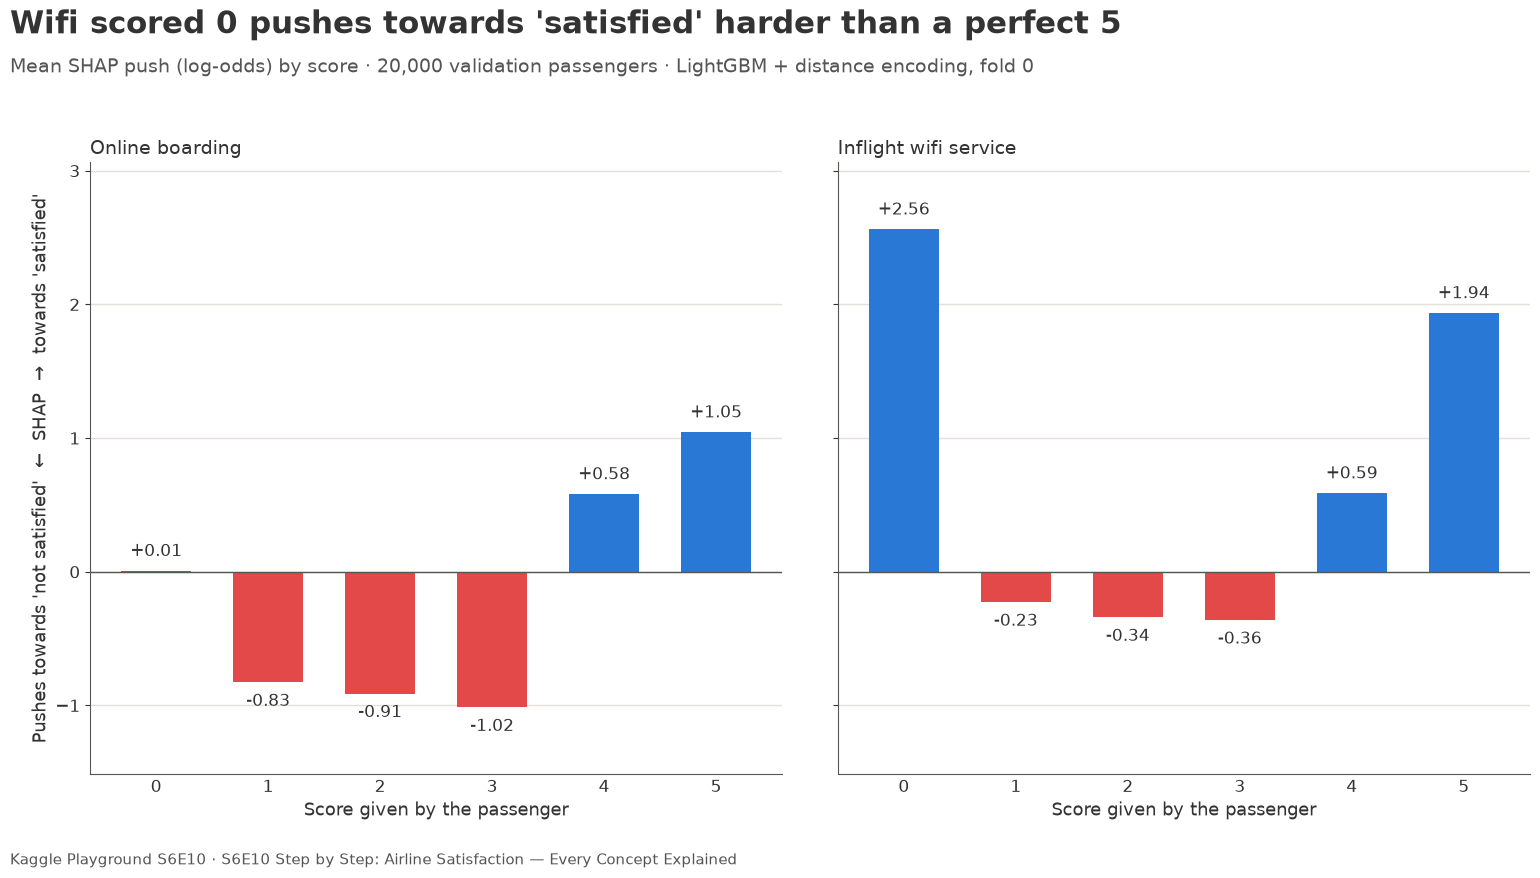

In [25]:
WIFI, BOARDING = "Inflight wifi service", "Online boarding"
by_score = pd.DataFrame({f: shap_values[f].groupby(sample[f]).mean() for f in [BOARDING, WIFI]}).reindex(range(6))
counts = pd.DataFrame({f: sample[f].value_counts() for f in [BOARDING, WIFI]}).reindex(range(6))
print(pd.concat({"mean SHAP": by_score.round(3), "rows in the sample": counts}, axis=1))

fig, axes = shareable_figure(
    title="Wifi scored 0 pushes towards 'satisfied' harder than a perfect 5",
    subtitle=f"Mean SHAP push (log-odds) by score · {len(sample):,} validation passengers · "
             f"LightGBM + distance encoding, fold 0",
    ncols=2, sharey=True,
)
for ax, f in zip(axes, [BOARDING, WIFI]):
    v = by_score[f]
    ax.bar(v.index, v, color=[BLUE if x > 0 else RED for x in v], width=0.62)
    for xi, x in v.items():
        ax.text(xi, x + (0.08 if x > 0 else -0.08), f"{x:+.2f}", ha="center", va="bottom" if x > 0 else "top",
                fontsize=12, color=DARK_GREY)
    ax.axhline(0, color=MID_GREY, lw=1)
    ax.set_title(f, loc="left", fontsize=14, color=DARK_GREY)
    ax.set_xticks(range(6), ["0", "1", "2", "3", "4", "5"])
    ax.set_xlabel("Score given by the passenger")
    ax.grid(axis="y", color=GRID, lw=1)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("Pushes towards 'not satisfied'  ←  SHAP  →  towards 'satisfied'")
low, high = by_score.min().min(), by_score.max().max()
axes[0].set_ylim(low - 0.5, high + 0.5)
fig.subplots_adjust(top=0.80, wspace=0.08)
plt.show()

What the model learned, in the language of the problem:

- **Online boarding has a threshold between 3 and 4.** Scores 1, 2 and 3 pull the prediction down by almost the same
  amount (−0.83 to −1.02); 4 and 5 push it up (+0.58 and +1.05). The passenger is not counting points: online
  boarding either worked for them or it did not. A `0` is neutral (+0.01) — the model treats it as "no information",
  which fits the "not applicable" reading.
- **For wifi, a `0` is the strongest signal of all: +2.56**, more than a perfect 5 (+1.94). Scores 1 to 3 are mildly
  negative (−0.23 to −0.36).

Two cautions. First, the `0` groups are small in this sample (248 passengers for online boarding, 366 for wifi), so
the exact height of those bars is less certain than the others. Second, SHAP describes **the model, not the
world**: it does not say that removing wifi would make passengers happier. A wifi score of `0` most likely marks a
kind of flight or of passenger that we cannot see in the columns (the data has no route, aircraft or fare), and the
model uses it as a stand-in. The honest statement is: *passengers with a 0 in wifi are, for reasons the data does
not show, far more often satisfied.*

# Part 9 — What helped and what did not

An honest ablation: each row changes one thing, all with the same folds.

In [26]:
summary = pd.DataFrame(RESULTS).T[["cv_mean", "cv_std", "oof"]]
summary["gain_vs_previous"] = summary["cv_mean"].diff()
summary.round(5)

,cv_mean,cv_std,oof,gain_vs_previous
Logistic regression (ratings as numbers),0.92156,0.00044,0.92156,NaN
Logistic regression (ratings one-hot),0.94859,0.00050,0.94859,0.02704
LightGBM (raw features),0.95882,0.00063,0.95881,0.01023
LightGBM + exact-distance target encoding,0.96009,0.00055,0.96008,0.00127


**What helped**

| Change | CV AUC before → after | Gain |
|---|---|---|
| Logistic regression: one-hot encode the 13 ratings instead of using them as numbers | 0.92156 → 0.94859 | +0.02704 |
| Replace logistic regression by LightGBM on the raw features | 0.94859 → 0.95882 | +0.01023 |
| Add the fold-safe target encoding of the exact flight distance | 0.95882 → 0.96009 | +0.00127 (5 folds out of 5) |

The gains shrink at every step. That is the normal shape of a tabular problem: the first sensible model takes most
of what there is, and here Part 7.5 suggests the rest is capped by label noise.

**What did not help (or helped less than expected)**

- **Ratings as plain numbers in a linear model**: 0.027 worse than one-hot. The scores are not monotonic, and a
  `0` is not below a `1`.
- **Binning the distance**: with distance alone, 405 bins reach 0.72510 against 0.74131 for the exact value. Every
  coarser version loses information.
- **More rows of the same kind**: a model trained on the 129,880 real rows scores 0.95437 on the synthetic train;
  training on 699,635 synthetic rows only brings 0.95882. Five times more data, +0.0044.
- **The delay columns**: around 1% of the model's attention. In the real survey they vary a lot; in the synthetic
  data 91% are zero.

**Not measured yet** — to be added here with their numbers in later versions, whether they help or not: adding the
original rows as extra training data, treating the `0` ratings as missing, and tuning the LightGBM parameters.

On the first of these, karttikjangid05 reports in the forum
([discussion](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/745098)) that adding the
original rows *lowered* the CV in a first test with short training, and that features built from the digits of the
flight distance helped — which points the same way as Part 7.

# Part 10 — Summary

**Key takeaways**

1. **Validation first.** Stratified 5-fold CV gives 0.95882 ± 0.00063 for the baseline and the public leaderboard
   says 0.95848. They agree to within one standard deviation, and train and test are indistinguishable, so the CV is
   the number to follow.
2. **Look at what a value means before feeding it to a model.** A rating of `0` is not a bad score, and scores 1 to
   3 are nearly the same thing. Respecting that is worth +0.027 AUC to a linear model, and a tree model gets it for
   free.
3. **The synthetic data keeps traces of the original.** The generator took the flight distances from the original
   list, and each exact distance carries its own satisfaction rate. A leak-free target encoding of that value adds
   +0.00127 AUC in CV, in all five folds, and +0.00125 on the public leaderboard.
4. **There is a ceiling.** The same model scores 0.995 on the real survey and 0.954 on the synthetic passengers;
   almost half of the baseline's errors are confident predictions with the opposite label. That part is noise, and
   no model will predict it.
5. **Interpretation agrees with the EDA.** The model leans on online boarding, type of travel, wifi, customer type
   and class — and on the encoded distance, in sixth place.

## Glossary

| Term | In one line |
|---|---|
| Binary classification | Predicting one of two outcomes, as a probability |
| Base rate | The share of positives in the whole dataset (44.4% here) |
| ROC AUC | Share of (satisfied, dissatisfied) pairs the model puts in the right order; only the order matters |
| EDA | Looking at the data before modelling, to learn what the model must deal with |
| Imputation | Filling a missing value (here, with the median) |
| Adversarial validation | Training a model to tell train from test; an AUC of 0.5 means they are alike |
| Overfitting | Memorising the training rows instead of learning what generalises |
| K-fold cross-validation | Train on K−1 parts, score on the remaining one, K times |
| Stratification | Keeping the same target share in every fold |
| Out-of-fold (OOF) prediction | A row's prediction from the model that did not train on it |
| Logistic regression | A weighted sum of the features turned into a probability |
| Standardisation | Rescaling a feature to mean 0 and standard deviation 1 |
| One-hot encoding | One 0/1 column per category |
| Interaction | When the effect of one feature depends on another |
| Gradient boosting | Many small trees, each correcting the errors of the previous ones |
| Early stopping | Stop adding trees when the validation score stops improving |
| Target encoding | Replacing a value by the average target of the rows that share it |
| Leakage | Information about the answer slipping into the features |
| Smoothing | Pulling a rate computed on few rows towards the overall rate |
| SHAP value | The push of one feature on one prediction: one line of the invoice |
| Log-odds | The model's internal scale, where pushes add up; the total is converted into a probability |

In [27]:
test_pred_final = test_pred_te
submission = pd.DataFrame({"id": test["id"], TARGET: test_pred_final})
submission.to_csv(OUTPUT / "submission.csv", index=False)
print(f"{len(submission):,} rows | mean prediction {test_pred_final.mean():.4f}")
submission.head()

299,844 rows | mean prediction 0.4440


,id,satisfaction
0,699635,0.193893
1,699636,0.898743
2,699637,0.919442
3,699638,0.065699
4,699639,0.044412


## References

- Competition: [Playground Series S6E10 — Predicting Airline Satisfaction](https://www.kaggle.com/competitions/playground-series-s6e10)
- Original dataset: [Binary Aviation Satisfaction (129k)](https://www.kaggle.com/datasets/arseniyshutko/binary-aviation-satisfaction-129k), by Arseniy Shutko (CC0)
- Exact values copied from the original dataset (the idea behind Part 7): Marc Maldonado Lorca,
  [the generator copied the original incomes and remembers their labels](https://www.kaggle.com/competitions/playground-series-s6e9/discussion/742385) (S6E9)
- The `0` rating as "not applicable": Ιωάννης Σταμελιάς,
  [Hidden Signals Unlocked…](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/744809)
- Original rows and flight-distance features in S6E10: karttikjangid05,
  [Which S6E10 tricks beat the noise?](https://www.kaggle.com/competitions/playground-series-s6e10/discussion/745098)
- The previous notebook in this series:
  [S6E9 Step by Step: Every Concept Explained](https://www.kaggle.com/code/nicolsbarcel/s6e9-step-by-step-every-concept-explained)

## Acknowledgements

This notebook was written with the assistance of Claude (Anthropic), an AI model. Analysis direction, review and
final decisions are the author's.